# 🌤️ Weather Data Analysis
### Mini Capstone Project

**Student Name:** Riya  
**Roll Number:** 2601201050  
**Project:** Weather Data Analysis using Python

## Aim
To clean and analyze daily weather readings, create useful features from dates, compare weather patterns, and present findings using tables and visualizations.

**Dataset note:** This notebook creates a synthetic sample dataset automatically. It is for demonstrating the analysis workflow, not reporting real-world weather observations.

**Run instructions:** In Google Colab, select **Runtime → Run all** to execute the notebook from top to bottom.

## 1. Load libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Setup complete — libraries are ready.")

Setup complete — libraries are ready.


## 2. Build a sample weather dataset
This version uses a different generation approach and chart style. Some readings are intentionally missing for the cleaning exercise.

In [2]:
random = np.random.default_rng(17)
calendar = pd.date_range("2025-01-01", periods=365, freq="D")
season_wave = np.cos(2 * np.pi * (calendar.dayofyear.to_numpy() - 200) / 365)

weather_df = pd.DataFrame({
    "date": calendar,
    "temperature_c": np.round(24 - 7 * season_wave + random.normal(0, 2.5, len(calendar)), 1),
    "rain_mm": np.round(random.exponential(3.2, len(calendar)), 1),
    "humidity_pct": np.round(np.clip(58 + 14 * season_wave + random.normal(0, 9, len(calendar)), 25, 100), 1)
})

# Rain is set to zero on some randomly selected days
dry_days = random.choice(weather_df.index, size=105, replace=False)
weather_df.loc[dry_days, "rain_mm"] = 0.0

# Add missing observations to demonstrate data cleaning
for column, count in [("temperature_c", 9), ("rain_mm", 11), ("humidity_pct", 7)]:
    chosen = random.choice(weather_df.index, size=count, replace=False)
    weather_df.loc[chosen, column] = np.nan

print(f"Dataset size: {weather_df.shape[0]} days × {weather_df.shape[1]} columns")
display(weather_df.head(7))

Dataset size: 365 days × 4 columns


,date,temperature_c,rain_mm,humidity_pct
0,2025-01-01,33.5,1.0,51.6
1,2025-01-02,31.6,0.0,44.7
2,2025-01-03,NaN,0.0,32.9
3,2025-01-04,27.7,0.8,35.2
4,2025-01-05,26.1,4.4,48.4
5,2025-01-06,30.9,4.1,40.6
6,2025-01-07,28.9,8.4,47.3


## 3. Inspect and clean the data

In [3]:
quality_report = pd.DataFrame({
    "Data type": weather_df.dtypes.astype(str),
    "Missing readings": weather_df.isna().sum(),
    "Missing (%)": (weather_df.isna().mean() * 100).round(2)
})
display(quality_report)

weather_df = weather_df.drop_duplicates().sort_values("date").reset_index(drop=True)
for column in ["temperature_c", "rain_mm", "humidity_pct"]:
    weather_df[column] = weather_df[column].fillna(weather_df[column].median())

print("Missing values after cleaning:")
display(weather_df.isna().sum().rename("Remaining missing values").to_frame())
print("Duplicate rows:", weather_df.duplicated().sum())

,Data type,Missing readings,Missing (%)
date,datetime64[ns],0,0.00
temperature_c,float64,9,2.47
rain_mm,float64,11,3.01
humidity_pct,float64,7,1.92


Missing values after cleaning:


,Remaining missing values
date,0
temperature_c,0
rain_mm,0
humidity_pct,0


Duplicate rows: 0


## 4. Create date features and temperature labels

In [4]:
weather_df["month_number"] = weather_df["date"].dt.month
weather_df["month"] = weather_df["date"].dt.strftime("%B")

def label_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    if month in [3, 4, 5]:
        return "Spring"
    if month in [6, 7, 8]:
        return "Summer"
    return "Autumn"

weather_df["season"] = weather_df["month_number"].map(label_season)
weather_df["temperature_band"] = pd.cut(
    weather_df["temperature_c"],
    bins=[-np.inf, 15, 25, 35, np.inf],
    labels=["Cold", "Mild", "Warm", "Very warm"],
    right=False
)

display(weather_df[["date", "month", "season", "temperature_c", "temperature_band"]].head(10))

,date,month,season,temperature_c,temperature_band
0,2025-01-01,January,Winter,33.5,Warm
1,2025-01-02,January,Winter,31.6,Warm
2,2025-01-03,January,Winter,23.9,Mild
3,2025-01-04,January,Winter,27.7,Warm
4,2025-01-05,January,Winter,26.1,Warm
5,2025-01-06,January,Winter,30.9,Warm
6,2025-01-07,January,Winter,28.9,Warm
7,2025-01-08,January,Winter,23.9,Mild
8,2025-01-09,January,Winter,30.4,Warm
9,2025-01-10,January,Winter,30.8,Warm


## 5. Monthly summary

In [5]:
monthly_report = weather_df.groupby(["month_number", "month"], as_index=False).agg(
    mean_temperature=("temperature_c", "mean"),
    rainfall_total=("rain_mm", "sum"),
    mean_humidity=("humidity_pct", "mean"),
    rainy_days=("rain_mm", lambda values: int((values > 0).sum()))
).sort_values("month_number")

display(monthly_report.round(2))

,month_number,month,mean_temperature,rainfall_total,mean_humidity,rainy_days
0,1,January,29.90,72.95,45.23,23
1,2,February,29.35,52.25,46.70,20
2,3,March,27.81,60.30,53.58,20
3,4,April,24.68,78.70,57.96,23
4,5,May,21.25,80.00,63.16,21
5,6,June,18.53,45.95,72.37,17
6,7,July,16.72,70.40,72.29,22
7,8,August,17.54,66.00,73.43,20
8,9,September,19.90,109.40,65.82,24
9,10,October,23.66,57.10,56.49,22


## 6. Visualize the results
These plots use a distinct style from the other notebook.

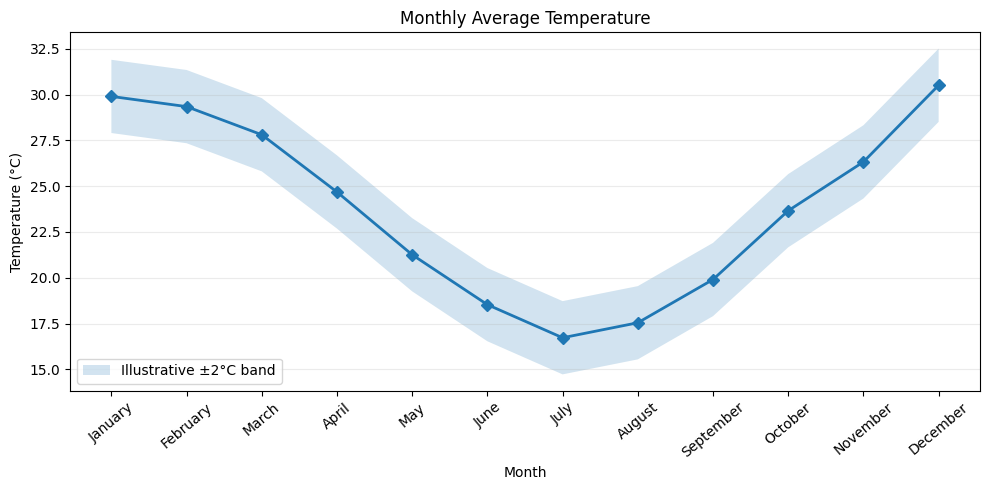

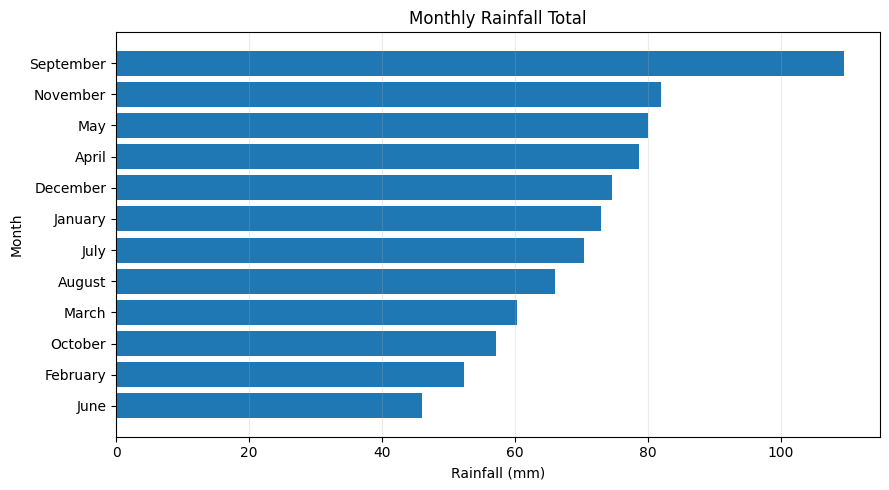

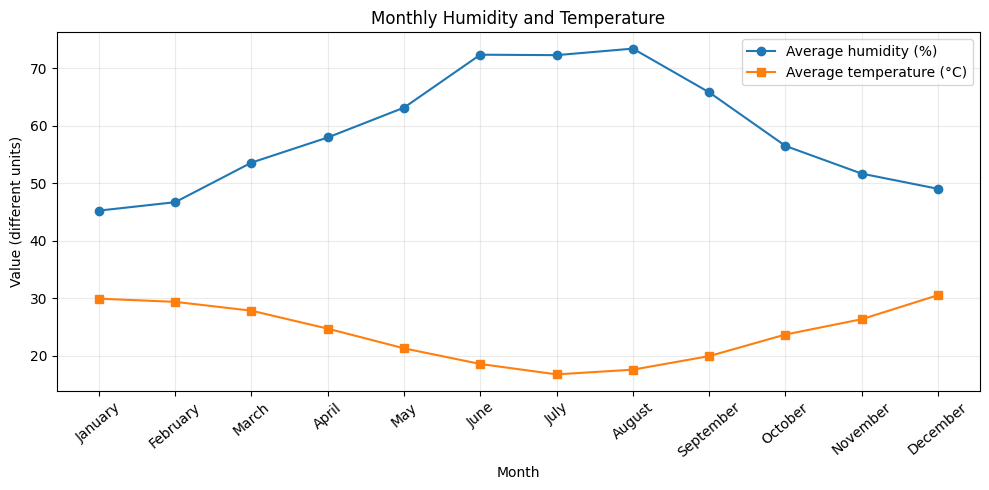

In [6]:
# Plot 1: Monthly temperature range
fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(
    monthly_report["month"],
    monthly_report["mean_temperature"] - 2,
    monthly_report["mean_temperature"] + 2,
    alpha=0.2,
    label="Illustrative ±2°C band"
)
ax.plot(monthly_report["month"], monthly_report["mean_temperature"], marker="D", linewidth=2)
ax.set_title("Monthly Average Temperature")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.tick_params(axis="x", rotation=40)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

# Plot 2: Rainfall by month as horizontal bars
fig, ax = plt.subplots(figsize=(9, 5))
ordered = monthly_report.sort_values("rainfall_total")
ax.barh(ordered["month"], ordered["rainfall_total"])
ax.set_title("Monthly Rainfall Total")
ax.set_xlabel("Rainfall (mm)")
ax.set_ylabel("Month")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

# Plot 3: Humidity and temperature together (separate scales avoided for clarity)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_report["month"], monthly_report["mean_humidity"], marker="o", label="Average humidity (%)")
ax.plot(monthly_report["month"], monthly_report["mean_temperature"], marker="s", label="Average temperature (°C)")
ax.set_title("Monthly Humidity and Temperature")
ax.set_xlabel("Month")
ax.set_ylabel("Value (different units)")
ax.tick_params(axis="x", rotation=40)
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()

## 7. Seasonal comparison

,season,avg_temperature,total_rainfall,avg_humidity
0,Winter,29.94,199.70,46.99
1,Spring,24.58,219.00,58.24
2,Summer,17.59,182.35,72.70
3,Autumn,23.30,248.40,57.98


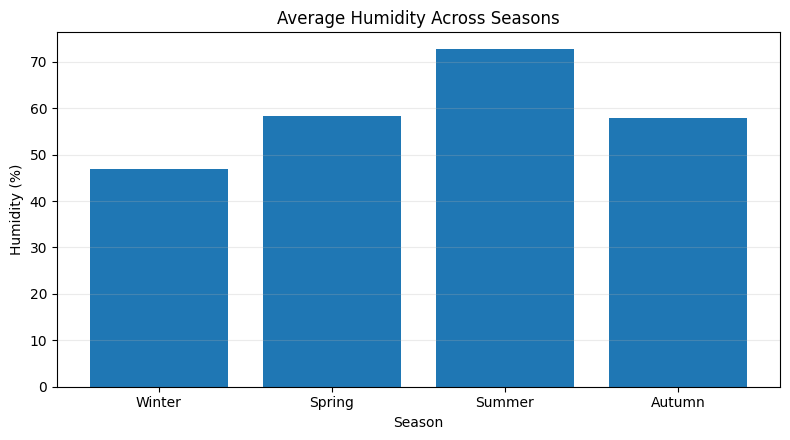

In [7]:
season_report = weather_df.groupby("season", observed=False).agg(
    avg_temperature=("temperature_c", "mean"),
    total_rainfall=("rain_mm", "sum"),
    avg_humidity=("humidity_pct", "mean")
).reindex(["Winter", "Spring", "Summer", "Autumn"]).reset_index()

display(season_report.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(season_report["season"], season_report["avg_humidity"])
ax.set_title("Average Humidity Across Seasons")
ax.set_xlabel("Season")
ax.set_ylabel("Humidity (%)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 8. Correlation analysis

,temperature_c,rain_mm,humidity_pct
temperature_c,1.00,0.00,-0.61
rain_mm,0.00,1.00,0.01
humidity_pct,-0.61,0.01,1.00


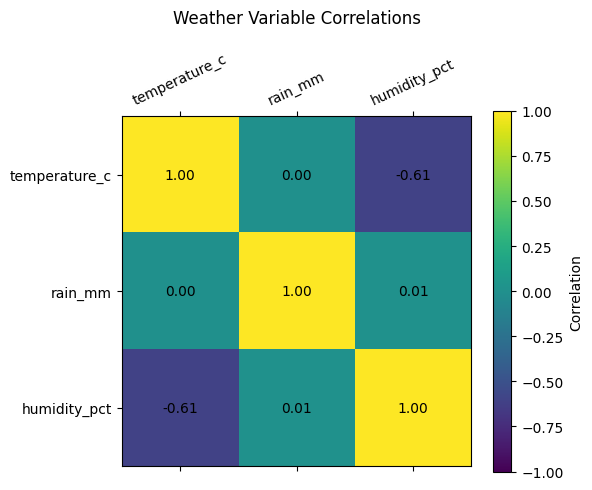

In [8]:
numeric_weather = weather_df[["temperature_c", "rain_mm", "humidity_pct"]]
corr_matrix = numeric_weather.corr()
display(corr_matrix.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
heat = ax.matshow(corr_matrix, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)), labels=corr_matrix.columns, rotation=25)
ax.set_yticks(range(len(corr_matrix.index)), labels=corr_matrix.index)
ax.set_title("Weather Variable Correlations", pad=20)
for row in range(corr_matrix.shape[0]):
    for col in range(corr_matrix.shape[1]):
        ax.text(col, row, f"{corr_matrix.iloc[row, col]:.2f}", ha="center", va="center")
fig.colorbar(heat, ax=ax, label="Correlation")
fig.tight_layout()
plt.show()

## 9. Key findings

In [9]:
warmest = monthly_report.loc[monthly_report["mean_temperature"].idxmax(), "month"]
coolest = monthly_report.loc[monthly_report["mean_temperature"].idxmin(), "month"]
rainiest = monthly_report.loc[monthly_report["rainfall_total"].idxmax(), "month"]
humid_season = season_report.loc[season_report["avg_humidity"].idxmax(), "season"]
common_band = weather_df["temperature_band"].mode().iloc[0]

print("KEY FINDINGS — SAMPLE DATA")
print(f"• Warmest month by average temperature: {warmest}")
print(f"• Coolest month by average temperature: {coolest}")
print(f"• Month with the greatest rainfall total: {rainiest}")
print(f"• Season with the highest average humidity: {humid_season}")
print(f"• Most frequent temperature band: {common_band}")

print("\nConclusion: This project demonstrates data cleaning, date feature extraction,")
print("temperature grouping, summary statistics, and weather visualization.")
print("The dataset is synthetic, so findings are not actual local weather measurements.")

KEY FINDINGS — SAMPLE DATA
• Warmest month by average temperature: December
• Coolest month by average temperature: July
• Month with the greatest rainfall total: September
• Season with the highest average humidity: Summer
• Most frequent temperature band: Mild

Conclusion: This project demonstrates data cleaning, date feature extraction,
temperature grouping, summary statistics, and weather visualization.
The dataset is synthetic, so findings are not actual local weather measurements.


## 10. Export cleaned data

In [10]:
csv_name = "riya_cleaned_weather_data.csv"
weather_df.to_csv(csv_name, index=False)
print(f"Export complete: {csv_name}")

try:
    from google.colab import files
    files.download(csv_name)
except ImportError:
    print("CSV saved in the notebook's working folder.")

Export complete: riya_cleaned_weather_data.csv
CSV saved in the notebook's working folder.
